# Lab Assignment 10 — NLP using Python-II
UCS420 Cognitive Computing

## Q1. Text preprocessing and word frequency

In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = "Artificial intelligence is changing the way people work and learn. I enjoy exploring technology because it helps solve real problems. Machine learning can find patterns in large amounts of data. Good software makes difficult tasks simpler and faster. I like learning how these tools work and how they can help people."

clean_text = re.sub(r'[^a-zA-Z0-9\s]', '', text.lower())
print("Original text:\n", text)
print("\nLowercase text without punctuation:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)
print("\nWord tokens:\n", words)
print("\nSentence tokens:\n", sentences)

split_words = clean_text.split()
print("\nPython split():\n", split_words)
print("\nNLTK word_tokenize():\n", word_tokenize(text))
print("\nComparison: split() separates text at whitespace, while word_tokenize() handles punctuation and language tokenization more carefully.")

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\nWords after stopword removal:\n", filtered_words)

freq = FreqDist(filtered_words)
print("\nWord frequency distribution:\n", freq.most_common())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original text:
 Artificial intelligence is changing the way people work and learn. I enjoy exploring technology because it helps solve real problems. Machine learning can find patterns in large amounts of data. Good software makes difficult tasks simpler and faster. I like learning how these tools work and how they can help people.

Lowercase text without punctuation:
 artificial intelligence is changing the way people work and learn i enjoy exploring technology because it helps solve real problems machine learning can find patterns in large amounts of data good software makes difficult tasks simpler and faster i like learning how these tools work and how they can help people

Word tokens:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'way', 'people', 'work', 'and', 'learn', 'i', 'enjoy', 'exploring', 'technology', 'because', 'it', 'helps', 'solve', 'real', 'problems', 'machine', 'learning', 'can', 'find', 'patterns', 'in', 'large', 'amounts', 'of', 'data', 'good', 'software

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## Q2. Stemming and lemmatization

In [2]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
filtered_alpha = [word for word in alphabetic_words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in filtered_alpha]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_alpha]

print("Alphabetic words:\n", alphabetic_words)
print("\nAfter stopword removal:\n", filtered_alpha)
print("\nStemmed words:\n", stemmed_words)
print("\nLemmatized words:\n", lemmatized_words)
print("\nStemming cuts words down to a root-like form and can produce non-dictionary words. Lemmatization returns dictionary forms. Stemming is useful for quick text matching, while lemmatization is better when readable and meaningful words matter.")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic words:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'way', 'people', 'work', 'and', 'learn', 'i', 'enjoy', 'exploring', 'technology', 'because', 'it', 'helps', 'solve', 'real', 'problems', 'machine', 'learning', 'can', 'find', 'patterns', 'in', 'large', 'amounts', 'of', 'data', 'good', 'software', 'makes', 'difficult', 'tasks', 'simpler', 'and', 'faster', 'i', 'like', 'learning', 'how', 'these', 'tools', 'work', 'and', 'how', 'they', 'can', 'help', 'people']

After stopword removal:
 ['artificial', 'intelligence', 'changing', 'way', 'people', 'work', 'learn', 'enjoy', 'exploring', 'technology', 'helps', 'solve', 'real', 'problems', 'machine', 'learning', 'find', 'patterns', 'large', 'amounts', 'data', 'good', 'software', 'makes', 'difficult', 'tasks', 'simpler', 'faster', 'like', 'learning', 'tools', 'work', 'help', 'people']

Stemmed words:
 ['artifici', 'intellig', 'chang', 'way', 'peopl', 'work', 'learn', 'enjoy', 'explor', 'technolog', 'help', 'solv', 'real',

## Q3. Bag of Words and TF-IDF

In [3]:
!pip -q install scikit-learn

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The new smartphone has a bright screen and a long battery life.",
    "Electric cars reduce pollution and can lower fuel costs.",
    "Online learning gives students flexible access to educational resources."
]

count_vectorizer = CountVectorizer(stop_words='english')
count_matrix = count_vectorizer.fit_transform(texts)
count_df = pd.DataFrame(count_matrix.toarray(), columns=count_vectorizer.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
print("Bag of Words representation:\n")
display(count_df)

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
print("TF-IDF scores:\n")
display(tfidf_df.round(3))

terms = tfidf_vectorizer.get_feature_names_out()
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    top_words = [(terms[j], round(row[j], 3)) for j in top_indices]
    print(f"Text {i + 1} top 3 keywords: {top_words}")
    print("Interpretation: These words have relatively high importance in this text compared with the other texts.\n")

Bag of Words representation:



,access,battery,bright,cars,costs,educational,electric,flexible,fuel,gives,...,long,lower,new,online,pollution,reduce,resources,screen,smartphone,students
Text 1,0,1,1,0,0,0,0,0,0,0,...,1,0,1,0,0,0,0,1,1,0
Text 2,0,0,0,1,1,0,1,0,1,0,...,0,1,0,0,1,1,0,0,0,0
Text 3,1,0,0,0,0,1,0,1,0,1,...,0,0,0,1,0,0,1,0,0,1


TF-IDF scores:



,access,battery,bright,cars,costs,educational,electric,flexible,fuel,gives,...,long,lower,new,online,pollution,reduce,resources,screen,smartphone,students
Text 1,0.000,0.378,0.378,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.378,0.000,0.378,0.000,0.000,0.000,0.000,0.378,0.378,0.000
Text 2,0.000,0.000,0.000,0.378,0.378,0.000,0.378,0.000,0.378,0.000,...,0.000,0.378,0.000,0.000,0.378,0.378,0.000,0.000,0.000,0.000
Text 3,0.354,0.000,0.000,0.000,0.000,0.354,0.000,0.354,0.000,0.354,...,0.000,0.000,0.000,0.354,0.000,0.000,0.354,0.000,0.000,0.354


Text 1 top 3 keywords: [('smartphone', np.float64(0.378)), ('screen', np.float64(0.378)), ('battery', np.float64(0.378))]
Interpretation: These words have relatively high importance in this text compared with the other texts.

Text 2 top 3 keywords: [('reduce', np.float64(0.378)), ('pollution', np.float64(0.378)), ('electric', np.float64(0.378))]
Interpretation: These words have relatively high importance in this text compared with the other texts.

Text 3 top 3 keywords: [('students', np.float64(0.354)), ('resources', np.float64(0.354)), ('flexible', np.float64(0.354))]
Interpretation: These words have relatively high importance in this text compared with the other texts.



## Q4. Similarity between two technology descriptions

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ai_text = "Artificial intelligence learns patterns from data. It supports prediction, automation, and decision making. AI systems are used in healthcare and education. They can improve speed and accuracy."
blockchain_text = "Blockchain stores records in linked blocks. It supports transparency, security, and decentralized transactions. Blockchain systems are used in finance and supply chains. They can improve trust and traceability."

def preprocess_words(value):
    return set(re.findall(r'\b[a-zA-Z]+\b', value.lower()))

ai_words = preprocess_words(ai_text)
blockchain_words = preprocess_words(blockchain_text)

print("AI tokens:\n", sorted(ai_words))
print("\nBlockchain tokens:\n", sorted(blockchain_words))

intersection = ai_words.intersection(blockchain_words)
union = ai_words.union(blockchain_words)
jaccard = len(intersection) / len(union) if union else 0

vectorizer = TfidfVectorizer(stop_words='english')
tfidf = vectorizer.fit_transform([ai_text, blockchain_text])
cosine = cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0]

print("\nCommon words:\n", sorted(intersection))
print("Jaccard similarity:", round(jaccard, 3))
print("Cosine similarity:", round(cosine, 3))
print("\nAnalysis: Jaccard measures the overlap between unique words and ignores their frequency. Cosine similarity compares TF-IDF weighted text vectors. Here, cosine similarity can give a more useful view of shared important terms, while Jaccard is a simple measure of vocabulary overlap.")

AI tokens:
 ['accuracy', 'ai', 'and', 'are', 'artificial', 'automation', 'can', 'data', 'decision', 'education', 'from', 'healthcare', 'improve', 'in', 'intelligence', 'it', 'learns', 'making', 'patterns', 'prediction', 'speed', 'supports', 'systems', 'they', 'used']

Blockchain tokens:
 ['and', 'are', 'blockchain', 'blocks', 'can', 'chains', 'decentralized', 'finance', 'improve', 'in', 'it', 'linked', 'records', 'security', 'stores', 'supply', 'supports', 'systems', 'they', 'traceability', 'transactions', 'transparency', 'trust', 'used']

Common words:
 ['and', 'are', 'can', 'improve', 'in', 'it', 'supports', 'systems', 'they', 'used']
Jaccard similarity: 0.256
Cosine similarity: 0.116

Analysis: Jaccard measures the overlap between unique words and ignores their frequency. Cosine similarity compares TF-IDF weighted text vectors. Here, cosine similarity can give a more useful view of shared important terms, while Jaccard is a simple measure of vocabulary overlap.


## Q5. Sentiment analysis and word cloud

In [6]:
!pip -q install textblob wordcloud matplotlib

Review 1: The headphones sound clear and the battery lasts a long time. I am very happy with this purchase.
Polarity: 0.362, Subjectivity: 0.546, Class: Positive

Review 2: The delivery was quick and the product works well. Great value for money.
Polarity: 0.567, Subjectivity: 0.625, Class: Positive

Review 3: The app is slow and crashes often. The support team did not solve my problem.
Polarity: -0.300, Subjectivity: 0.400, Class: Negative

Review 4: The package arrived late and the item stopped working after two days.
Polarity: -0.300, Subjectivity: 0.600, Class: Negative

Review 5: The product is okay and works as expected.
Polarity: 0.200, Subjectivity: 0.450, Class: Positive



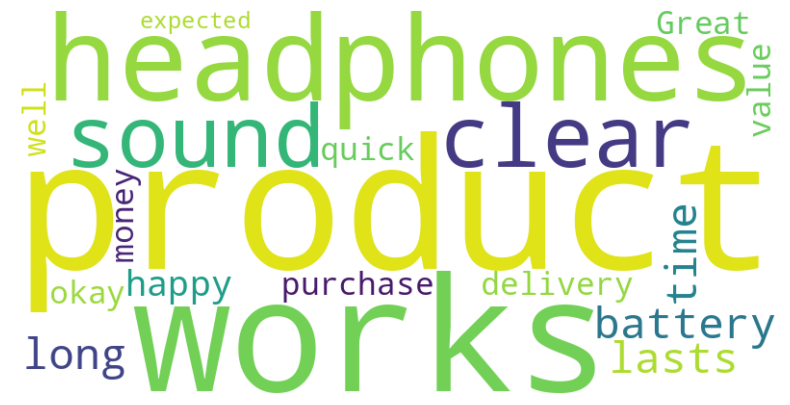

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "The headphones sound clear and the battery lasts a long time. I am very happy with this purchase.",
    "The delivery was quick and the product works well. Great value for money.",
    "The app is slow and crashes often. The support team did not solve my problem.",
    "The package arrived late and the item stopped working after two days.",
    "The product is okay and works as expected."
]

positive_reviews = []

for i, review in enumerate(reviews, start=1):
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity
    if polarity > 0:
        label = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        label = "Negative"
    else:
        label = "Neutral"
    print(f"Review {i}: {review}")
    print(f"Polarity: {polarity:.3f}, Subjectivity: {subjectivity:.3f}, Class: {label}\n")

positive_text = " ".join(positive_reviews)
if positive_text.strip():
    wordcloud = WordCloud(width=800, height=400, background_color='white', stopwords=set(stopwords.words('english'))).generate(positive_text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()
else:
    print("No positive reviews available for the word cloud.")

## Q6. Text generation using an LSTM

In [8]:
!pip -q install tensorflow

In [9]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = """Technology changes the way people communicate and solve problems. Learning new skills takes patience and regular practice. Small projects help students understand important ideas. Good software is built through testing, feedback, and improvement. Data can reveal patterns and support better decisions. Creative thinking helps people find useful solutions. A simple idea can become valuable when it solves a real problem. Developers learn from mistakes and improve their work over time. Reading, experimenting, and sharing knowledge help a team grow. Building useful technology requires curiosity, effort, and responsibility."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
sequences = []

for line in training_text.split('.'):
    token_list = tokenizer.texts_to_sequences([line.strip()])[0]
    for i in range(1, len(token_list)):
        sequences.append(token_list[:i + 1])

max_sequence_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_sequence_len, padding='pre')
X = sequences[:, :-1]
y = sequences[:, -1]
y = np.eye(total_words)[y]

model = Sequential([
    Embedding(total_words, 16, input_length=max_sequence_len - 1),
    LSTM(32),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=100, verbose=0)
print("Model training completed.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model training completed.


In [10]:
def generate_text(seed_text, next_words=12):
    result = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding='pre')
        predicted = int(np.argmax(model.predict(token_list, verbose=0), axis=-1)[0])
        output_word = next((word for word, index in tokenizer.word_index.items() if index == predicted), "")
        if not output_word:
            break
        result += " " + output_word
    return result

print(generate_text("technology", 10) + ".")
print(generate_text("learning", 10) + ".")
print(generate_text("good software", 10) + ".")

technology can and and and and practice problems time time real.
learning useful can and and and practice problems time time real.
good software useful useful and and and improvement practice problems time time.
